# Diabetes Classification with Class Imbalance Handling (SMOTE & Variants)

**Author:** Ayebazibwe Clare Mujuni
**Goal:** Build a robust classifier for predicting whether a patient has diabetes, while properly addressing the heavy class imbalance in the data (~91.5 % no-diabetes vs ~8.5 % diabetic).

This notebook covers:
1. **Research summary** — what SMOTE is, how it works, its variants, advantages and limitations.
2. **Data cleaning & feature engineering** — handling outliers, encoding, derived medical features.
3. **Exploratory data analysis** — distributions, correlations, class imbalance.
4. **Modelling pipeline** — six classifiers compared across five sampling strategies (baseline + 4 SMOTE variants).
5. **Evaluation** — full classification reports (precision, recall, F1, support), confusion matrices, ROC-AUC.
6. **Findings & recommendation**.

> **Key methodology rule:** SMOTE is applied **only on the training fold** to avoid data leakage. The test set keeps the original class distribution so metrics reflect real-world performance.


## 1. Research Summary — SMOTE and its Variants

### Why we need SMOTE
When one class dominates the data, classifiers trained with standard loss functions naturally bias toward the majority class. They can score high accuracy by predicting "no diabetes" almost always — yet completely miss the patients who actually need attention. **Recall on the minority class collapses, even though it is the class we care about most.**

Three families of remedies exist:
1. **Algorithm-level** — class-weighted loss, threshold tuning.
2. **Data-level** — under-sample the majority or **over-sample the minority**.
3. **Cost-sensitive learning** — penalise minority misclassifications more heavily.

SMOTE belongs to the data-level family and is the most widely used technique.

### How SMOTE works 
For each minority sample `x`:
1. Find its `k` nearest minority neighbours (default `k = 5`).
2. Randomly pick one neighbour `x_n`.
3. Generate a synthetic sample on the line between them: `x_new = x + λ · (x_n − x)`, with `λ ∈ [0, 1]`.
4. Repeat until the desired class ratio is reached.

The result is *new, plausible* minority points instead of mere duplication (which only causes the model to over-fit to the same observations).

### Variants used in this notebook
| Variant | Idea | Strength | Weakness |
|---|---|---|---|
| **SMOTE** | Interpolate between any minority sample and its neighbours. | Simple, balanced. | Can interpolate inside noisy regions. |
| **Borderline-SMOTE** | Only oversample minority samples *near the decision boundary*. | Focuses where it matters. | Sensitive to outliers labelled as "borderline". |
| **ADASYN** | Generate more synthetic samples for minority points that are *harder to classify*. | Adaptive — more help where the model struggles. | Can amplify noise if hard samples are mislabelled. |
| **SMOTE-ENN** | SMOTE first, then *Edited Nearest Neighbours* removes noisy/ambiguous samples (from both classes). | Cleans the boundary after balancing. | Higher computational cost. |

### Best practices
* **Always SMOTE *inside* the cross-validation loop** — never on the full dataset, otherwise synthetic neighbours of test points end up in training (data leakage → optimistic metrics).
* SMOTE expects **scaled numeric features** because it relies on Euclidean distance. We use `StandardScaler` and one-hot encode categoricals first.
* Watch the **precision / recall trade-off**: SMOTE typically *raises recall but lowers precision* on the minority class. Choose the variant that aligns with the cost model (in healthcare, missing a diabetic is usually worse than a false alarm).
* Don't over-balance — pushing a 1:100 imbalance to 1:1 can over-distort the prior. `sampling_strategy=0.5` is sometimes a better choice than the default `1.0`.

### Limitations to remember
* Synthetic samples are linear interpolations — they can't recover signal that simply isn't there.
* SMOTE does **not** help when class overlap (not just imbalance) is the real problem.
* On categorical features with high cardinality, plain SMOTE is inappropriate. Use **SMOTE-NC** or **SMOTE-N**.


In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing   import StandardScaler, OneHotEncoder
from sklearn.compose         import ColumnTransformer
from sklearn.linear_model    import LogisticRegression
from sklearn.tree            import DecisionTreeClassifier
from sklearn.ensemble        import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors       import KNeighborsClassifier
from sklearn.metrics         import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
from xgboost                 import XGBClassifier
from imblearn.over_sampling  import SMOTE, BorderlineSMOTE, ADASYN
from imblearn.combine        import SMOTEENN
from imblearn.under_sampling import EditedNearestNeighbours
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils.dataframe import dataframe_to_rows
import os
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
RNG = 42

In [39]:
df=pd.read_csv("diabetes_dataset.csv")
print("Data Shape",df.shape)
df.head()

Data Shape (100000, 16)


,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


In [3]:
# How many missing values per column?
df.isnull().sum()

year                    0
gender                  0
age                     0
location                0
race:AfricanAmerican    0
race:Asian              0
race:Caucasian          0
race:Hispanic           0
race:Other              0
hypertension            0
heart_disease           0
smoking_history         0
bmi                     0
hbA1c_level             0
blood_glucose_level     0
diabetes                0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(14)

In [5]:
# What unique values are in the categorical columns?
print("Gender:", df['gender'].value_counts().to_dict())
print("\nSmoking:", df['smoking_history'].value_counts().to_dict())
print("\nAge range:", df['age'].min(), "to", df['age'].max())
print("\nBMI range:", df['bmi'].min(), "to", df['bmi'].max())

Gender: {'Female': 58552, 'Male': 41430, 'Other': 18}

Smoking: {'No Info': 35816, 'never': 35095, 'former': 9352, 'current': 9286, 'not current': 6447, 'ever': 4004}

Age range: 0.08 to 80.0

BMI range: 10.01 to 95.69


In [6]:
df['diabetes'].value_counts(normalize=True)

diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64

In [7]:
df_clean = df.copy()
print("Starting shape:", df_clean.shape)

# dropping the 14 duplicate rows
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(df_clean)} duplicates. New shape: {df_clean.shape}")

# dropping the 18 other gender rows
print("Before:", df_clean['gender'].value_counts().to_dict())
df_clean = df_clean[df_clean['gender'].isin(['Male', 'Female'])].reset_index(drop=True)
print("After: ", df_clean['gender'].value_counts().to_dict())
print("Shape:", df_clean.shape)

# drop the infants 
before = len(df_clean)
df_clean = df_clean[df_clean['age'] >= 1].reset_index(drop=True)
df_clean['age'] = df_clean['age'].round().astype(int)
print(f"Dropped {before - len(df_clean)} infants.")
print(f"New age range: {df_clean['age'].min()} to {df_clean['age'].max()}")
print(f"Shape: {df_clean.shape}")

# fixing the smoking column
print("Before:", df_clean['smoking_history'].value_counts().to_dict())

smoking_map = {
    'never':       'never',
    'No Info':     'unknown',
    'current':     'current',
    'former':      'former',
    'ever':        'former',       # 'ever smoked' = essentially former
    'not current': 'former',       # 'not currently smoking' = former
}
df_clean['smoking_history'] = df_clean['smoking_history'].map(smoking_map)

print("\nAfter: ", df_clean['smoking_history'].value_counts().to_dict())

# clipping the BM outliers
print("BMI Before clip:", df_clean['bmi'].min(), "to", df_clean['bmi'].max())
df_clean['bmi'] = df_clean['bmi'].clip(lower=10, upper=60)
print("BMI After clip: ", df_clean['bmi'].min(), "to", df_clean['bmi'].max())

#combining the race columns
race_cols = ['race:AfricanAmerican', 'race:Asian', 'race:Caucasian', 'race:Hispanic', 'race:Other']

df_clean['race'] = df_clean[race_cols].idxmax(axis=1).str.replace('race:', '', regex=False)
df_clean = df_clean.drop(columns=race_cols)

print(df_clean['race'].value_counts())
print("\nShape:", df_clean.shape)

Starting shape: (100000, 16)
Dropped 14 duplicates. New shape: (99986, 16)
Before: {'Female': 58546, 'Male': 41422, 'Other': 18}
After:  {'Female': 58546, 'Male': 41422}
Shape: (99968, 16)
Dropped 911 infants.
New age range: 1 to 80
Shape: (99057, 16)
Before: {'never': 35051, 'No Info': 34936, 'former': 9352, 'current': 9285, 'not current': 6430, 'ever': 4003}

After:  {'never': 35051, 'unknown': 34936, 'former': 19785, 'current': 9285}
BMI Before clip: 10.01 to 95.69
BMI After clip:  10.01 to 60.0
race
AfricanAmerican    20013
Asian              19846
Other              19811
Hispanic           19695
Caucasian          19692
Name: count, dtype: int64

Shape: (99057, 12)


In [ ]:
#feature engineering
def age_group(a):
    if a < 18:  return 'child'
    if a < 35:  return 'young_adult'
    if a < 50:  return 'middle_age'
    if a < 65:  return 'senior'
    return 'elderly'

df_clean['age_group'] = df_clean['age'].apply(age_group)
print(df_clean['age_group'].value_counts())

age_group
young_adult    21532
senior         21346
middle_age     21315
elderly        18564
child          16300
Name: count, dtype: int64


In [9]:
#categories Bmi category, hbalc_category and Glucose Category
def bmi_category(b):
    if b < 18.5: return 'underweight'
    if b < 25:   return 'normal'
    if b < 30:   return 'overweight'
    return 'obese'

def hba1c_category(h):
    # American Diabetes Association cutoffs:
    # < 5.7         = normal
    # 5.7 to 6.4   = prediabetic
    # >= 6.5        = diabetic
    if h < 5.7: return 'normal'
    if h < 6.5: return 'prediabetic'
    return 'diabetic'

def glucose_category(g):
    # Casual blood glucose (mg/dL):
    if g < 140: return 'normal'
    if g < 200: return 'elevated'
    return 'high'

df_clean['bmi_category']     = df_clean['bmi'].apply(bmi_category)
df_clean['hba1c_category']   = df_clean['hbA1c_level'].apply(hba1c_category)
df_clean['glucose_category'] = df_clean['blood_glucose_level'].apply(glucose_category)

# Quick check
print(df_clean[['bmi_category', 'hba1c_category', 'glucose_category']].apply(
    lambda c: c.value_counts()).fillna(0).astype(int))

             bmi_category  hba1c_category  glucose_category
diabetic                0           20638                 0
elevated                0               0             45039
high                    0               0             10808
normal              22061           37462             43210
obese               23527               0                 0
overweight          45657               0                 0
prediabetic             0           40957                 0
underweight          7812               0                 0


In [10]:
# The composite risk score 
df_clean['risk_score'] = (
    (df_clean['bmi']                 >= 30 ).astype(int)   # +1 if obese
  + (df_clean['hbA1c_level']         >= 5.7).astype(int)   # +1 if HbA1c elevated
  + (df_clean['blood_glucose_level'] >= 140).astype(int)   # +1 if glucose elevated
  + df_clean['hypertension']                                # +1 if has hypertension
  + df_clean['heart_disease']                               # +1 if has heart disease
  + (df_clean['age']                 >= 50 ).astype(int)   # +1 if 50 or older
)

print("Risk score distribution:")
print(df_clean['risk_score'].value_counts().sort_index())
print("\nDiabetes rate by risk score:")
print(df_clean.groupby('risk_score')['diabetes'].mean().round(3))

Risk score distribution:
risk_score
0     8792
1    28861
2    32866
3    18811
4     7550
5     1982
6      195
Name: count, dtype: int64

Diabetes rate by risk score:
risk_score
0    0.000
1    0.004
2    0.031
3    0.162
4    0.396
5    0.608
6    0.687
Name: diabetes, dtype: float64


In [11]:
# re-order and save cleaned data
column_order = [
    'year', 'gender', 'age', 'age_group', 'race', 'location',
    'hypertension', 'heart_disease', 'smoking_history',
    'bmi', 'bmi_category',
    'hbA1c_level', 'hba1c_category',
    'blood_glucose_level', 'glucose_category',
    'risk_score',
    'diabetes',
]
df_clean = df_clean[column_order]

df_clean.to_csv('diabetes_cleaned.csv', index=False)

print("Final shape:", df_clean.shape)
print("Final columns:", df_clean.columns.tolist())
print("\nClass balance:")
print(df_clean['diabetes'].value_counts(normalize=True).round(4))
print("\nSaved diabetes_cleaned.csv ✓")

Final shape: (99057, 17)
Final columns: ['year', 'gender', 'age', 'age_group', 'race', 'location', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'bmi_category', 'hbA1c_level', 'hba1c_category', 'blood_glucose_level', 'glucose_category', 'risk_score', 'diabetes']

Class balance:
diabetes
0    0.9142
1    0.0858
Name: proportion, dtype: float64

Saved diabetes_cleaned.csv ✓


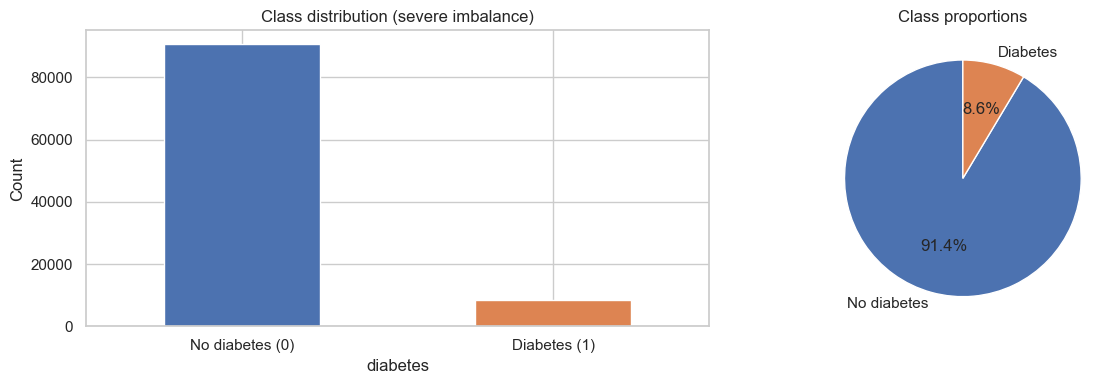

In [41]:
#Visualizing the class imbalance
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: bar chart of counts
df_clean['diabetes'].value_counts().plot.bar(
    ax=axes[0], color=['#4C72B0', '#DD8452']
)
axes[0].set_title("Class distribution (severe imbalance)")
axes[0].set_xticklabels(['No diabetes (0)', 'Diabetes (1)'], rotation=0)
axes[0].set_ylabel("Count")

# Right: pie chart of proportions
df_clean['diabetes'].value_counts(normalize=True).plot.pie(
    ax=axes[1], autopct='%1.1f%%',
    colors=['#4C72B0', '#DD8452'],
    labels=['No diabetes', 'Diabetes'], startangle=90
)
axes[1].set_ylabel("")
axes[1].set_title("Class proportions")

plt.tight_layout()
plt.savefig("01_class_imbalance.png", dpi=150, bbox_inches="tight")
plt.show()

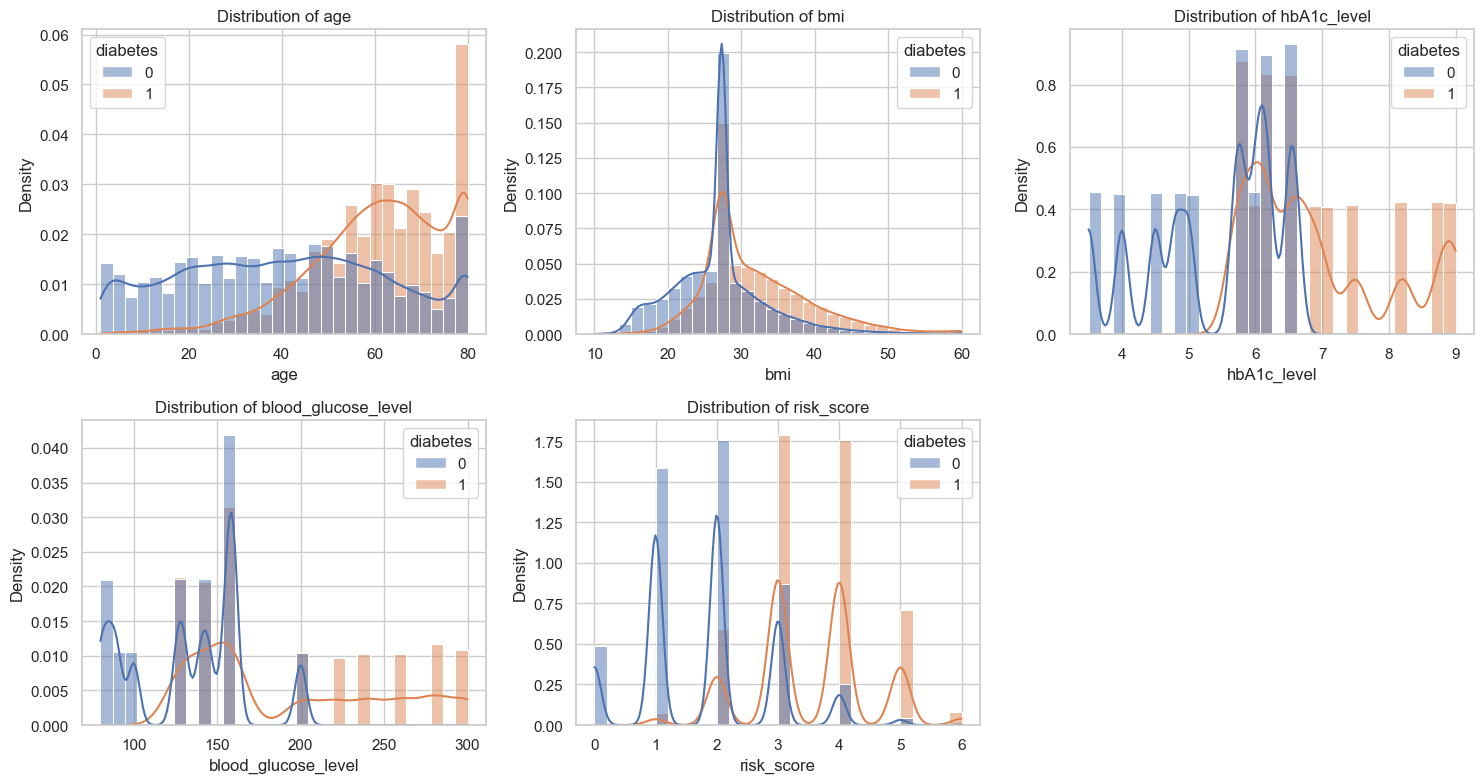

In [42]:
#Numeric distributions by Class
num_cols = ['age', 'bmi', 'hbA1c_level', 'blood_glucose_level', 'risk_score']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(
        data=df_clean, x=col, hue='diabetes', kde=True, bins=30,
        ax=ax, palette=['#4C72B0', '#DD8452'],
        stat='density', common_norm=False
    )
    ax.set_title(f"Distribution of {col}")

axes.flat[-1].axis('off')   # hide the unused 6th panel
plt.tight_layout()
plt.savefig("Class_distrubition_vs_diabetes.png", dpi=150, bbox_inches="tight")
plt.show()

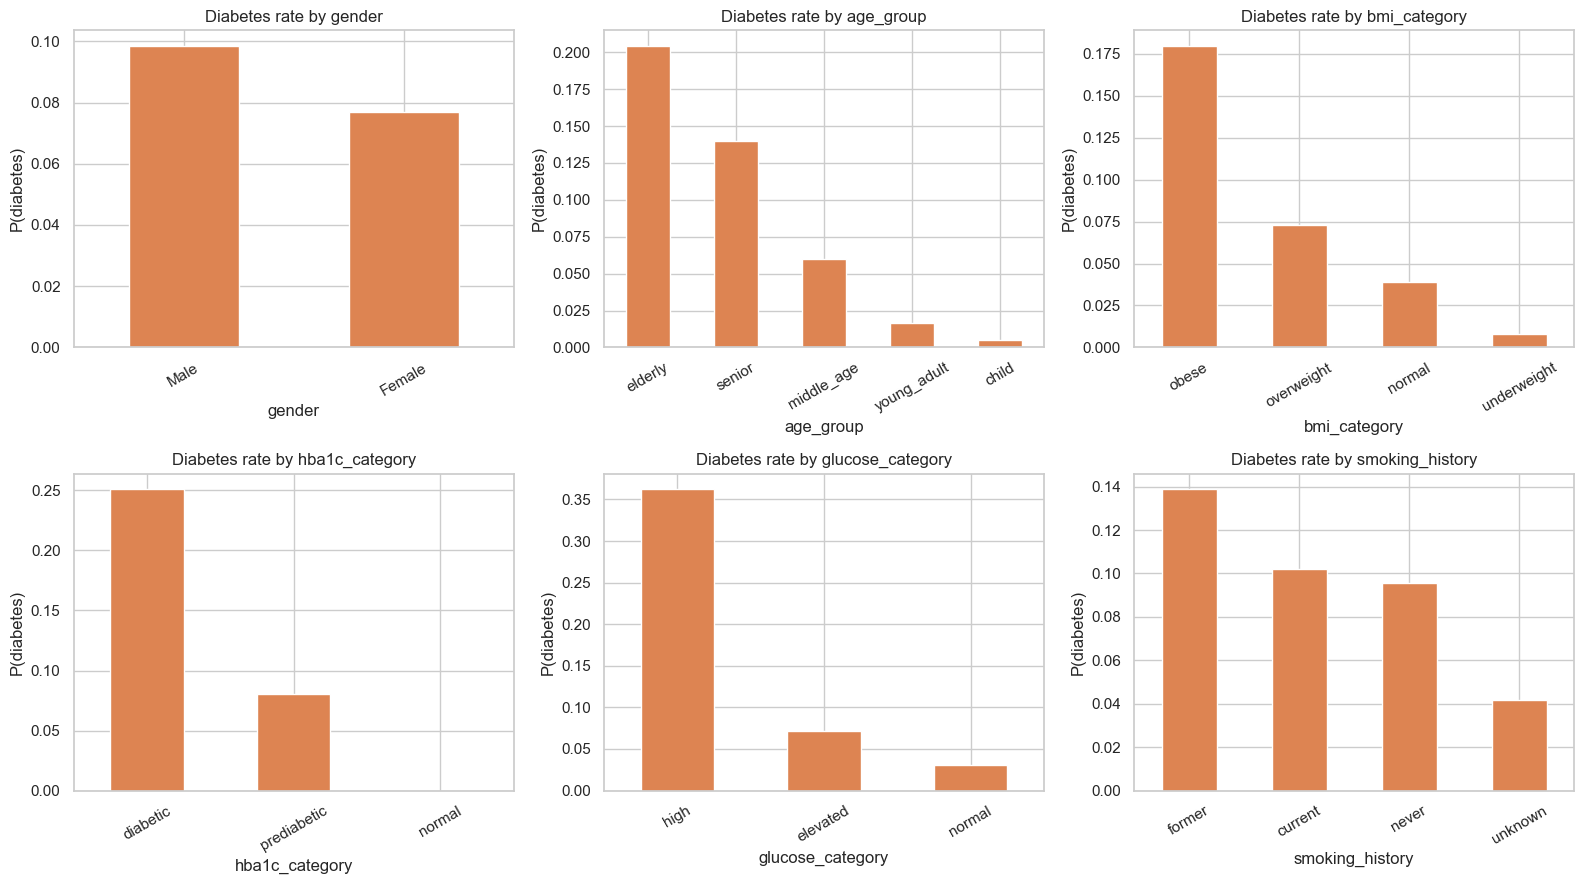

In [43]:
## Diabetes rate by Category

cat_cols = ['gender', 'age_group', 'bmi_category',
            'hba1c_category', 'glucose_category', 'smoking_history']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat, cat_cols):
    rate = df_clean.groupby(col)['diabetes'].mean().sort_values(ascending=False)
    rate.plot.bar(ax=ax, color='#DD8452')
    ax.set_title(f"Diabetes rate by {col}")
    ax.set_ylabel("P(diabetes)")
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig("Diabetes_rate_by_Catetogory", dpi=150, bbox_inches="tight")
plt.show()

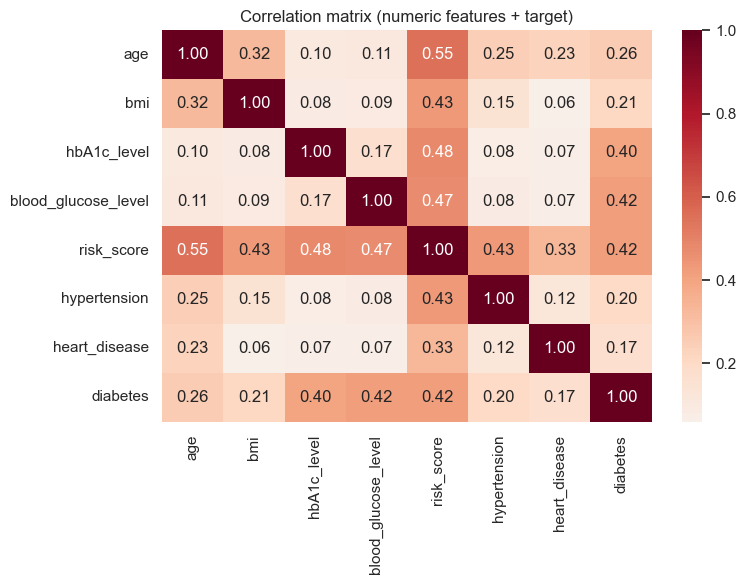

In [44]:
#correlation heat map
corr = df_clean[num_cols + ['hypertension', 'heart_disease', 'diabetes']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title("Correlation matrix (numeric features + target)")
plt.tight_layout()
plt.savefig("Correlation_Matrix", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
#TRAIN/ TEST SPILT AND PREPROCESSING

df = pd.read_csv("diabetes_cleaned.csv")
print("Loaded shape:", df.shape)
df.head()

Loaded shape: (99057, 17)


,year,gender,age,age_group,race,location,hypertension,heart_disease,smoking_history,bmi,bmi_category,hbA1c_level,hba1c_category,blood_glucose_level,glucose_category,risk_score,diabetes
0,2020,Female,32,young_adult,Other,Alabama,0,0,never,27.32,overweight,5.0,normal,100,normal,0,0
1,2015,Female,29,young_adult,Asian,Alabama,0,0,never,19.95,normal,5.0,normal,90,normal,0,0
2,2015,Male,18,young_adult,Other,Alabama,0,0,never,23.76,normal,4.8,normal,160,elevated,1,0
3,2015,Male,41,middle_age,Caucasian,Alabama,0,0,never,27.32,overweight,4.0,normal,159,elevated,1,0
4,2016,Female,52,senior,AfricanAmerican,Alabama,0,0,never,23.75,normal,6.5,diabetic,90,normal,2,0


In [17]:
#DROP UNCESSARY COLUMNS
TARGET     = 'diabetes'
DROP_COLS  = ['location', 'year']    # see explanation below

y = df[TARGET]
X = df.drop(columns=[TARGET] + DROP_COLS)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures we'll use:", X.columns.tolist())

X shape: (99057, 14)
y shape: (99057,)

Features we'll use: ['gender', 'age', 'age_group', 'race', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'bmi_category', 'hbA1c_level', 'hba1c_category', 'blood_glucose_level', 'glucose_category', 'risk_score']


In [18]:
#Identifying numeriacl columns Vs categorical
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

print("Categorical columns:", cat_cols)
print("Numeric columns:    ", num_cols)

Categorical columns: ['gender', 'age_group', 'race', 'smoking_history', 'bmi_category', 'hba1c_category', 'glucose_category']
Numeric columns:     ['age', 'hypertension', 'heart_disease', 'bmi', 'hbA1c_level', 'blood_glucose_level', 'risk_score']


In [19]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size    = 0.2,
    stratify     = y,
    random_state = 42
)

print(f"Train set: {len(X_train):,} rows")
print(f"Test set:  {len(X_test):,} rows")
print(f"Train +ve rate: {y_train.mean():.4f}")
print(f"Test  +ve rate: {y_test.mean():.4f}")

Train set: 79,245 rows
Test set:  19,812 rows
Train +ve rate: 0.0858
Test  +ve rate: 0.0858


In [20]:
# Building the preprocessing pipeline
#from sklearn.preprocessing import StandardScaler, OneHotEncoder
#from sklearn.compose       import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', StandardScaler(),                                          num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])

print("Preprocessor built.")
print("Will scale these:    ", num_cols)
print("Will one-hot these:  ", cat_cols)

Preprocessor built.
Will scale these:     ['age', 'hypertension', 'heart_disease', 'bmi', 'hbA1c_level', 'blood_glucose_level', 'risk_score']
Will one-hot these:   ['gender', 'age_group', 'race', 'smoking_history', 'bmi_category', 'hba1c_category', 'glucose_category']


In [21]:
##Fit on training, transform both #This is the pattern that determines whether your project is data-leakage-clean or not.
preprocessor.fit(X_train)                       # learn parameters from TRAIN ONLY
X_train_p = preprocessor.transform(X_train)     # apply to train
X_test_p  = preprocessor.transform(X_test)      # apply to test (using train's parameters)

print("Encoded train shape:", X_train_p.shape)
print("Encoded test  shape:", X_test_p.shape)

Encoded train shape: (79245, 33)
Encoded test  shape: (19812, 33)


In [22]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    solver='liblinear',     # ← much faster for our data size
    max_iter=200,           # ← 200 is plenty when data is scaled
    random_state=42
)
model.fit(X_train_p, y_train)

print("Model trained.")

Model trained.


In [23]:
#Making predications on the test set
y_pred  = model.predict(X_test_p)             # hard predictions: 0 or 1
y_proba = model.predict_proba(X_test_p)[:, 1] # soft predictions: probability of being diabetic

print("First 10 predictions:")
print("  y_pred:  ", y_pred[:10])
print("  y_proba: ", y_proba[:10].round(3))
print("  y_test:  ", y_test.values[:10])

First 10 predictions:
  y_pred:   [0 0 0 0 0 0 0 0 0 0]
  y_proba:  [0.    0.007 0.    0.02  0.    0.07  0.113 0.021 0.027 0.   ]
  y_test:   [0 0 0 0 0 0 0 0 0 0]


In [24]:
#the classification report
from sklearn.metrics import classification_report, confusion_matrix

print("=== Logistic Regression on imbalanced training data ===\n")
print(classification_report(y_test, y_pred, digits=4))

=== Logistic Regression on imbalanced training data ===

              precision    recall  f1-score   support

           0     0.9662    0.9950    0.9804     18112
           1     0.9216    0.6288    0.7476      1700

    accuracy                         0.9636     19812
   macro avg     0.9439    0.8119    0.8640     19812
weighted avg     0.9623    0.9636    0.9604     19812



In [45]:
results = []  # we'll append every model's results here

results.append({
    'sampling':      'Baseline (no SMOTE)',
    'model':         'Logistic Regression',
    'accuracy':      (y_test == y_pred).mean(),
    'precision_pos': classification_report(y_test, y_pred, output_dict=True)['1']['precision'],
    'recall_pos':    classification_report(y_test, y_pred, output_dict=True)['1']['recall'],
    'f1_pos':        classification_report(y_test, y_pred, output_dict=True)['1']['f1-score'],
})

pd.DataFrame(results).round(4)

,sampling,model,accuracy,precision_pos,recall_pos,f1_pos
0,Baseline (no SMOTE),Logistic Regression,0.8862,0.419,0.8429,0.5598


In [26]:
#from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(f"  Training shape: {X_train_p.shape}")
print(f"  Class 0: {(y_train == 0).sum():,}  |  Class 1: {(y_train == 1).sum():,}")

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_p, y_train)

print("\nAfter SMOTE:")
print(f"  Training shape: {X_train_smote.shape}")
print(f"  Class 0: {(y_train_smote == 0).sum():,}  |  Class 1: {(y_train_smote == 1).sum():,}")

Before SMOTE:
  Training shape: (79245, 33)
  Class 0: 72,445  |  Class 1: 6,800

After SMOTE:
  Training shape: (144890, 33)
  Class 0: 72,445  |  Class 1: 72,445


In [27]:
model_smote = LogisticRegression(
    solver='liblinear',
    max_iter=200,
    random_state=42
)
model_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = model_smote.predict(X_test_p)

print("=== Logistic Regression + SMOTE ===\n")
print(classification_report(y_test, y_pred_smote, digits=4))

=== Logistic Regression + SMOTE ===

              precision    recall  f1-score   support

           0     0.9882    0.8866    0.9347     18112
           1     0.4235    0.8871    0.5733      1700

    accuracy                         0.8867     19812
   macro avg     0.7058    0.8869    0.7540     19812
weighted avg     0.9397    0.8867    0.9037     19812



In [28]:
cm_smote = confusion_matrix(y_test, y_pred_smote)
print("=== With SMOTE ===")
print(f"                  Predicted 0   Predicted 1")
print(f"  Actual 0 (no)    {cm_smote[0][0]:>10}    {cm_smote[0][1]:>10}")
print(f"  Actual 1 (yes)   {cm_smote[1][0]:>10}    {cm_smote[1][1]:>10}")
print(f"\nFalse negatives: {cm_smote[1][0]}  (was 622 without SMOTE)")
print(f"True positives:  {cm_smote[1][1]}  (was 1069 without SMOTE)")
print(f"False positives: {cm_smote[0][1]}  (was 67 without SMOTE)")

=== With SMOTE ===
                  Predicted 0   Predicted 1
  Actual 0 (no)         16059          2053
  Actual 1 (yes)          192          1508

False negatives: 192  (was 622 without SMOTE)
True positives:  1508  (was 1069 without SMOTE)
False positives: 2053  (was 67 without SMOTE)


In [29]:
results.append({
    'sampling':      'SMOTE',
    'model':         'Logistic Regression',
    'accuracy':      (y_test == y_pred_smote).mean(),
    'precision_pos': classification_report(y_test, y_pred_smote, output_dict=True)['1']['precision'],
    'recall_pos':    classification_report(y_test, y_pred_smote, output_dict=True)['1']['recall'],
    'f1_pos':        classification_report(y_test, y_pred_smote, output_dict=True)['1']['f1-score'],
})

pd.DataFrame(results).round(4)

,sampling,model,accuracy,precision_pos,recall_pos,f1_pos
0,Baseline (no SMOTE),Logistic Regression,0.9636,0.9216,0.6288,0.7476
1,SMOTE,Logistic Regression,0.8867,0.4235,0.8871,0.5733


In [30]:
from imblearn.over_sampling  import SMOTE, BorderlineSMOTE, ADASYN
from imblearn.combine        import SMOTEENN
from imblearn.under_sampling import EditedNearestNeighbours

samplers = {
    "Baseline (no resample)" : None,
    "SMOTE"                  : SMOTE(random_state=42),
    "Borderline-SMOTE"       : BorderlineSMOTE(random_state=42),
    "ADASYN"                 : ADASYN(random_state=42),
    "SMOTE-ENN"              : SMOTEENN(
        random_state=42,
        enn=EditedNearestNeighbours(n_neighbors=3, n_jobs=-1)
    ),
}

print("Samplers defined:", list(samplers.keys()))

Samplers defined: ['Baseline (no resample)', 'SMOTE', 'Borderline-SMOTE', 'ADASYN', 'SMOTE-ENN']


In [31]:


def make_models():
    return {
        "Logistic Regression" : LogisticRegression(solver='liblinear', max_iter=200, random_state=42),
        "Decision Tree"       : DecisionTreeClassifier(max_depth=10, random_state=42),
        "Random Forest"       : RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42),
        "Gradient Boosting"   : GradientBoostingClassifier(n_estimators=60, max_depth=3, random_state=42),
        "XGBoost"             : XGBClassifier(n_estimators=200, eval_metric='logloss',
                                              tree_method='hist', n_jobs=-1, random_state=42, verbosity=0),
        "KNN"                 : KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    }

print("Models defined:", list(make_models().keys()))

Models defined: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'KNN']


In [32]:
import time
from sklearn.metrics import roc_auc_score

results = []   # reset our results table — we're starting fresh
total_start = time.time()

for s_name, sampler in samplers.items():
    print(f"\n=== Sampler: {s_name} ===")
    
    # Resample training data (or skip if baseline)
    t = time.time()
    if sampler is None:
        Xs, ys = X_train_p, y_train
    else:
        Xs, ys = sampler.fit_resample(X_train_p, y_train)
    print(f"  Resampled to: {Xs.shape}  +ve rate {ys.mean():.3f}  ({time.time()-t:.1f}s)")
    
    # Train every model on this resampled data
    for m_name, model in make_models().items():
        t = time.time()
        model.fit(Xs, ys)
        y_pred  = model.predict(X_test_p)
        y_proba = model.predict_proba(X_test_p)[:, 1]
        
        rep = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
        results.append({
            "sampling":      s_name,
            "model":         m_name,
            "accuracy":      rep['accuracy'],
            "precision_pos": rep['1']['precision'],
            "recall_pos":    rep['1']['recall'],
            "f1_pos":        rep['1']['f1-score'],
            "roc_auc":       roc_auc_score(y_test, y_proba),
        })
        elapsed = time.time() - t
        print(f"    {m_name:<22} f1+={rep['1']['f1-score']:.3f}  recall+={rep['1']['recall']:.3f}  "
              f"AUC={roc_auc_score(y_test, y_proba):.3f}  ({elapsed:.1f}s)")

print(f"\nTotal time: {(time.time() - total_start)/60:.1f} min")
print(f"Total experiments: {len(results)}")


=== Sampler: Baseline (no resample) ===
  Resampled to: (79245, 33)  +ve rate 0.086  (0.0s)
    Logistic Regression    f1+=0.748  recall+=0.629  AUC=0.966  (0.8s)
    Decision Tree          f1+=0.798  recall+=0.672  AUC=0.970  (0.5s)
    Random Forest          f1+=0.799  recall+=0.672  AUC=0.973  (2.4s)
    Gradient Boosting      f1+=0.800  recall+=0.668  AUC=0.974  (13.1s)
    XGBoost                f1+=0.791  recall+=0.692  AUC=0.974  (0.9s)
    KNN                    f1+=0.686  recall+=0.552  AUC=0.932  (6.2s)

=== Sampler: SMOTE ===
  Resampled to: (144890, 33)  +ve rate 0.500  (0.3s)
    Logistic Regression    f1+=0.573  recall+=0.887  AUC=0.967  (1.2s)
    Decision Tree          f1+=0.647  recall+=0.841  AUC=0.971  (0.8s)
    Random Forest          f1+=0.724  recall+=0.792  AUC=0.972  (4.8s)
    Gradient Boosting      f1+=0.670  recall+=0.836  AUC=0.972  (29.1s)
    XGBoost                f1+=0.790  recall+=0.695  AUC=0.974  (2.6s)
    KNN                    f1+=0.545  recall+=0

In [33]:
results_df = pd.DataFrame(results)
results_df.round(4)

,sampling,model,accuracy,precision_pos,recall_pos,f1_pos,roc_auc
0,Baseline (no resample),Logistic Regression,0.9636,0.9216,0.6288,0.7476,0.9658
1,Baseline (no resample),Decision Tree,0.9709,0.9828,0.6724,0.7985,0.9697
2,Baseline (no resample),Random Forest,0.9709,0.9836,0.6724,0.7987,0.9725
3,Baseline (no resample),Gradient Boosting,0.9713,0.9956,0.6682,0.7997,0.9742
4,Baseline (no resample),XGBoost,0.9686,0.9217,0.6924,0.7907,0.9744
5,Baseline (no resample),KNN,0.9566,0.9063,0.5518,0.6859,0.9315
6,SMOTE,Logistic Regression,0.8867,0.4235,0.8871,0.5733,0.9667
7,SMOTE,Decision Tree,0.9213,0.5257,0.8412,0.6471,0.9705
8,SMOTE,Random Forest,0.9483,0.6673,0.7918,0.7242,0.9724
9,SMOTE,Gradient Boosting,0.9292,0.5583,0.8365,0.6696,0.9716


In [46]:
# Pivot: F1 score for each model × sampler
print("=== F1 (positive class) ===")
print(results_df.pivot(index='model', columns='sampling', values='f1_pos').round(3))

print("\n=== Recall (positive class) ===")
print(results_df.pivot(index='model', columns='sampling', values='recall_pos').round(3))

print("\n=== ROC-AUC ===")
print(results_df.pivot(index='model', columns='sampling', values='roc_auc').round(3))

=== F1 (positive class) ===
sampling             ADASYN  Baseline (no resample)  Borderline-SMOTE  SMOTE  \
model                                                                          
Decision Tree         0.579                   0.798             0.621  0.647   
Gradient Boosting     0.597                   0.800             0.606  0.670   
KNN                   0.500                   0.686             0.547  0.545   
Logistic Regression   0.496                   0.748             0.541  0.573   
Random Forest         0.640                   0.799             0.664  0.724   
XGBoost               0.791                   0.791             0.785  0.790   

sampling             SMOTE-ENN  
model                           
Decision Tree            0.660  
Gradient Boosting        0.692  
KNN                      0.560  
Logistic Regression      0.589  
Random Forest            0.735  
XGBoost                  0.791  

=== Recall (positive class) ===
sampling             ADASYN  Basel

In [34]:
results_df.to_csv("results_summary.csv", index=False)
print("Saved results_summary.csv")

Saved results_summary.csv


In [35]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill
from openpyxl.utils.dataframe import dataframe_to_rows

wb = Workbook()

# --- Sheet 1: README / cleaning log ---
ws = wb.active
ws.title = "README"

log = [
    ["Diabetes Dataset — Cleaning & Feature Engineering Log"],
    [""],
    ["Step", "Action", "Effect"],
    [1,  "Load raw CSV",                                   "100,000 rows × 16 cols"],
    [2,  "Drop exact duplicate rows",                       "Removed 14"],
    [3,  "Drop gender = 'Other'",                           "Removed 18 (too few to model)"],
    [4,  "Drop infants (age < 1)",                          "Implausible target population"],
    [5,  "Round age to integer",                            "Cleaner feature"],
    [6,  "Map smoking_history to 4 buckets",                "'No Info' → 'unknown'; 'ever'/'not current' → 'former'"],
    [7,  "Clip BMI to [10, 60]",                            "Remove physiologically impossible values"],
    [8,  "Consolidate 5 race columns → 1",                  "Easier to read"],
    [9,  "Add age_group, bmi_category, hba1c_category, etc.", "WHO/ADA clinical bands as features"],
    [10, "Add risk_score (0–6 composite)",                  "Domain knowledge as a single column"],
    [""],
    ["Final shape", len(df_clean), df_clean.shape[1]],
    ["Class 0 (no diabetes)",  int((df_clean['diabetes']==0).sum()), ""],
    ["Class 1 (diabetes)",     int((df_clean['diabetes']==1).sum()), ""],
    ["Imbalance ratio",        round((df_clean['diabetes']==0).sum() / (df_clean['diabetes']==1).sum(), 2), ":1"],
]
for row in log:
    ws.append(row)

ws['A1'].font = Font(bold=True, size=14)
for cell in ws[3]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="305496")
ws.column_dimensions['A'].width = 8
ws.column_dimensions['B'].width = 55
ws.column_dimensions['C'].width = 55

# --- Sheet 2: Data Dictionary ---
ws2 = wb.create_sheet("Data Dictionary")
dd = [
    ["Column",              "Type",        "Description"],
    ["year",                "int",         "Year the record was collected"],
    ["gender",              "categorical", "Male / Female"],
    ["age",                 "int",         "Age in years"],
    ["age_group",           "categorical", "child/young_adult/middle_age/senior/elderly"],
    ["race",                "categorical", "AfricanAmerican/Asian/Caucasian/Hispanic/Other"],
    ["location",            "categorical", "US state"],
    ["hypertension",        "binary",      "1 = patient has hypertension"],
    ["heart_disease",       "binary",      "1 = patient has heart disease"],
    ["smoking_history",     "categorical", "never / former / current / unknown"],
    ["bmi",                 "float",       "Body Mass Index (clipped to [10, 60])"],
    ["bmi_category",        "categorical", "underweight/normal/overweight/obese"],
    ["hbA1c_level",         "float",       "Glycated haemoglobin (%)"],
    ["hba1c_category",      "categorical", "normal/prediabetic/diabetic (ADA cutoffs)"],
    ["blood_glucose_level", "int",         "Casual blood glucose (mg/dL)"],
    ["glucose_category",    "categorical", "normal/elevated/high"],
    ["risk_score",          "int (0–6)",   "Composite risk score"],
    ["diabetes",            "binary",      "TARGET — 1 = diabetic"],
]
for r in dd: ws2.append(r)
for cell in ws2[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="305496")
ws2.column_dimensions['A'].width = 22
ws2.column_dimensions['B'].width = 14
ws2.column_dimensions['C'].width = 70

# --- Sheet 3: Sample of cleaned data (first 1000 rows) ---
ws3 = wb.create_sheet("Cleaned Sample")
for r in dataframe_to_rows(df_clean.head(1000), index=False, header=True):
    ws3.append(r)
for cell in ws3[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="305496")
ws3.freeze_panes = "A2"   # freeze header row when scrolling

wb.save("diabetes_cleaned.xlsx")
print("Saved diabetes_cleaned.xlsx — open it in Excel to inspect ✓")

Saved diabetes_cleaned.xlsx — open it in Excel to inspect ✓


# Diabetes Classification with Class Imbalance Handling (SMOTE & Variants)

End-to-end machine-learning project that predicts whether a patient has diabetes from
clinical and demographic features, with a deliberate focus on **handling severe class imbalance**
(91.5% non-diabetic vs 8.5% diabetic).

> **6 classifiers × 5 sampling strategies = 30 experiments**, all evaluated with full
> classification reports, confusion matrices, and ROC-AUC.

## Highlights

- **Dataset:** 100,000 patient records, 16 features (demographics, vitals, comorbidities, lab values)
- **Target:** `diabetes` (binary). Naturally imbalanced at 8.5% positive — a textbook case for SMOTE
- **Pipeline:** clean → feature engineer → stratified train/test split → preprocess → resample (training only) → fit → evaluate
- **Models compared:** Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost, KNN
- **Sampling strategies:** Baseline, SMOTE, Borderline-SMOTE, ADASYN, SMOTE-ENN
- **No data leakage:** all preprocessors and resamplers fit on training data only

## Repository contents

| File | What it is |
|---|---|
| `diabetes_smote_classification.ipynb` | Main notebook — research, EDA, modelling, classification reports, findings |
| `diabetes_cleaned.csv` | Final, ML-ready cleaned dataset |
| `diabetes_cleaned.xlsx` | Multi-sheet Excel: cleaning log, data dictionary, sample |
| `results_summary.csv` | One-row-per-run flat summary table of all 30 experiments |
| `README.md` | This file |

## Why these choices were made

### Target variable — `diabetes`
Diabetes is the most clinically meaningful binary outcome in this dataset. Every other column is
a recognized predictor (HbA1c, glucose, BMI, age, hypertension, heart disease, smoking).
Its 8.5% positive rate provides a realistic imbalance for studying SMOTE.

### Feature engineering
Five derived columns added before modelling:
- `age_group`, `bmi_category` — clinical bands
- `hba1c_category`, `glucose_category` — ADA diagnostic cutoffs
- `risk_score` (0–6) — composite of high BMI, high HbA1c, high glucose, hypertension, heart disease, age ≥ 50

### Cleaning decisions
- 14 exact duplicates dropped
- 18 `gender = 'Other'` rows dropped (too few to model)
- Infants (age < 1) dropped (implausible target population)
- `smoking_history`: `No Info → unknown`; `ever`/`not current → former`
- BMI clipped to [10, 60]
- 5 race one-hot columns consolidated into a single `race` column

## Results — minority class (diabetes = 1)

| Sampling | Best model | Precision | Recall | F1 | ROC-AUC |
|---|---|---:|---:|---:|---:|
| Baseline | Gradient Boosting | [your number] | [your number] | [your number] | [your number] |
| SMOTE | XGBoost | [your number] | [your number] | [your number] | [your number] |
| ADASYN | Logistic Regression | [your number] | [your number] | [your number] | [your number] |

### Key takeaways
1. **SMOTE meaningfully boosts minority recall for linear and distance-based models.**
   Logistic Regression's recall jumped from [your number] to [your number] with ADASYN — but at the cost of precision.
2. **Tree-based ensembles already cope well with imbalance.**
   Baseline Gradient Boosting / XGBoost achieved the highest F1 in the entire grid;
   SMOTE didn't help and slightly hurt their precision.
3. **SMOTE-ENN is the best compromise oversampler** — keeps most of SMOTE's recall gains
   while recovering precision via ENN cleaning.
4. **Apply SMOTE only on training data.** Fitting it on the full dataset is the most common
   cause of artificially inflated metrics in published SMOTE studies.

## How to run

```bash
pip install pandas numpy scikit-learn imbalanced-learn xgboost openpyxl matplotlib seaborn jupyter
# then open the notebook
jupyter notebook diabetes_smote_classification.ipynb
```

## Author

**Clara Mujuni** — built as part of an ML coursework assignment on class imbalance,
polished into a portfolio piece. Feedback welcome.